In [12]:
import glob
import time
import re
import gc

from functions import *
from functions_stage2 import (get_rainfall_cube_subsection, find_max_precip_location_new, 
                        find_temporal_profile_new, maybe_diagnose, analyse_peak_event,
                             plot_cluster_check,get_rainfall_lookback_cube)

# ── Config ────────────────────────────────────────────────────────────────────
from config import RAINFALL_CSV_DIR, CATCHMENT_LOOKUP_DICT, OUT_DIR, CATCHMENTS, ENSEMBLE_MEMBERS 

## ------------------------------------------------------------ ###
## Define which catchments to run
## ------------------------------------------------------------ ###

In [2]:
all_catchments = set(CATCHMENT_LOOKUP_DICT.keys())
files = os.listdir(OUT_DIR)
completed_catchments = {re.search(r'Catchment_(.+)', f).group(1) for f in files if re.search(r'Catchment_(.+)', f)}
catchments_to_run = (all_catchments - completed_catchments) - {105} - {14}

catchments_with_flood_output = []

## Loop through all catchments
for catchment_num in all_catchments:
    catchment_name = CATCHMENT_LOOKUP_DICT[catchment_num]
    fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails/Catchment_{catchment_num}/{catchment_name}.pkl"
    flood_fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/PluvialResults/5km_total/Catchment_{catchment_num}/Ens01_{catchment_num}/10cm/flooded_area_5km_total_Ens01_{catchment_num}_10cm.nc"
        
    if os.path.isfile(flood_fp):
        catchments_with_flood_output.append(catchment_num)

## ------------------------------------------------------------ ###
## Define test catchment / ensemble member
## ------------------------------------------------------------ ###

In [9]:
catchment_num = '23'
ens_num = '01'
catchment_name = CATCHMENT_LOOKUP_DICT[catchment_num]

boundary_gdf    = CATCHMENTS[CATCHMENTS['HA_NUM'] == str(catchment_num)]
CATCHMENT_POLY = boundary_gdf.geometry.iloc[0]

fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails/Catchment_{catchment_num}/{catchment_name}.pkl"
flood_fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/PluvialResults/5km_total/Catchment_{catchment_num}/Ens01_{catchment_num}/10cm/flooded_area_5km_total_Ens01_{catchment_num}_10cm.nc"
flood_dir    = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/PluvialResults/5km_total/Catchment_{catchment_num}/"

## ------------------------------------------------------------ ###
## Find if the cell with the largest area and largest volume flooded are always the same
## ------------------------------------------------------------ ###

In [17]:
flood_numpy = {}
flood_cubes = {}
current_ens = None
DIAGNOSE_EVENT = [0]
n_days_ls      = [2, 3, 4, 5]       # antecedent SM windows
rain_n_days_ls = [1, 2, 5, 10]      # NEW — antecedent rainfall windows
all_results    = []

In [10]:
full_rain_cube = get_rainfall_cube_subsection(2015, '01', f"/scratch/hydro5/users/ld14116/SDM_bias_correction/Hourly/01/", 1, 2)
FULL_MASK_2D   = mask_cube_with_catchment_full_grid(full_rain_cube[0], CATCHMENT_POLY, method='center_point')
year_cube, mask_x_offset, mask_y_offset = subset_cube_to_bbox(full_rain_cube, CATCHMENT_POLY, buffer=0)
ny_sub = year_cube.shape[1]
nx_sub = year_cube.shape[2]
mask_2d_sub = FULL_MASK_2D[mask_y_offset:mask_y_offset + ny_sub, 
                            mask_x_offset:mask_x_offset + nx_sub]
# print(f"Mask created in {time.time()-begin_time:.1f}s")
del full_rain_cube, year_cube

In [18]:
def peak_cell(field):
    """Return (y, x, n_ties) of the max cell, or None if there's no flooding."""
    if np.all(np.isnan(field)) or np.nanmax(field) <= 0:
        return None
    mx = np.nanmax(field)
    y, x = np.unravel_index(np.nanargmax(field), field.shape)
    return int(y), int(x), int(np.sum(field == mx))

check_rows = []

rainfall_events = pd.read_csv(RAINFALL_CSV_DIR + f"{catchment_name}_{ens_num}_full_events_with_event_nums.csv")
rainfall_events['event_num']  = range(1, len(rainfall_events) + 1)
rainfall_events['hydro_year'] = rainfall_events['start_year'].where(
    rainfall_events['start_month'] != 12, rainfall_events['start_year'] + 1)

# load flood arrays ONCE per ensemble (10cm only)
flood_dir    = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/PluvialResults/5km_total/Catchment_{catchment_num}/"
ens_flood_dir = f"{flood_dir}/Ens{ens_num}_{catchment_num}/"
flood_np = {}
for metric in ['area', 'volume']:
    cube = prepare_flood_cube(load_3d_cube(
        f"{ens_flood_dir}/10cm/flooded_{metric}_5km_total_Ens{ens_num}_{catchment_num}_10cm.nc"))
    cube.data = np.where(FULL_MASK_2D, cube.data, np.nan)
    cube = filter_closer_to_catchment(cube, CATCHMENT_POLY, plot=False)
    flood_np[metric] = cube.data

for year, events_in_year in rainfall_events.groupby('hydro_year'):
    for row in events_in_year.itertuples():
        event_num = int(row.event_num)

        area_ev = flood_np['area'][event_num - 1]
        vol_ev  = flood_np['volume'][event_num - 1]

        pk_area = peak_cell(area_ev)
        pk_vol  = peak_cell(vol_ev)

        check_rows.append({
            'catchment': catchment_num,
            'ens': ens_num,
            'event_num': event_num,
            'area_y':     pk_area[0] if pk_area else np.nan,
            'area_x':     pk_area[1] if pk_area else np.nan,
            'area_nties': pk_area[2] if pk_area else 0,
            'vol_y':      pk_vol[0]  if pk_vol  else np.nan,
            'vol_x':      pk_vol[1]  if pk_vol  else np.nan,
            'vol_nties':  pk_vol[2]  if pk_vol  else 0,
        })

del flood_np
gc.collect()

check_df = pd.DataFrame(check_rows)

In [19]:
PEAK_DEPTH  = 30        # cm
PEAK_METRIC = 'vol'     # 'vol' or 'area'

flood_ev = flood_numpy[PEAK_DEPTH][PEAK_METRIC][event_num - 1]   # (y, x)
assert flood_ev.shape == year_cube.shape[1:], \
    f"Flood grid {flood_ev.shape} != rainfall bbox grid {year_cube.shape[1:]}"

if np.all(np.isnan(flood_ev)) or np.nanmax(flood_ev) <= 0:
    # no flooding: record the event but skip cell-based extraction
    results_dict = {'no_flood': True}
    results_this_ens.append({**event_meta, **results_dict})   # event_meta = the csv-derived fields
    # continue

y_idx, x_idx = np.unravel_index(np.nanargmax(flood_ev), flood_ev.shape)

flood_ref_cube = flood_cubes[PEAK_DEPTH]['area']
results_dict = {'x_idx': int(x_idx), 'y_idx': int(y_idx),
    'x_idx_global': int(x_idx + x_offset), 'y_idx_global': int(y_idx + y_offset),
    'x_coord': float(flood_ref_cube.coord('projection_x_coordinate').points[x_idx]),
    'y_coord': float(flood_ref_cube.coord('projection_y_coordinate').points[y_idx]),
    'no_flood': False,}

rainfall_at_peak = get_data_at_peak_cell(year_cube, results_dict, 'x_idx', 'y_idx')

plt.plot(rainfall_at_peak.data)

results_dict['max_precip_flood_peak_cell'] = np.nanmax(rainfall_at_peak.data)

KeyError: 30

In [6]:
# import gc

# def peak_cell(field):
#     """Return (y, x, n_ties) of the max cell, or None if there's no flooding."""
#     if np.all(np.isnan(field)) or np.nanmax(field) <= 0:
#         return None
#     mx = np.nanmax(field)
#     y, x = np.unravel_index(np.nanargmax(field), field.shape)
#     return int(y), int(x), int(np.sum(field == mx))

# DEPTH = 10
# PRIMARY_METRIC = 'vol'   # volume is less prone to ties than area

# def peak_cells_all_events(arr):
#     """arr: (n_events, y, x). Returns a DataFrame of peak cell per event."""
#     n = arr.shape[0]
#     flat   = arr.reshape(n, -1)
#     filled = np.where(np.isnan(flat), -np.inf, flat)   # all-NaN rows -> max = -inf
#     mx     = filled.max(axis=1)
#     idx    = filled.argmax(axis=1)
#     n_ties = (filled == mx[:, None]).sum(axis=1)
#     y, x   = np.unravel_index(idx, arr.shape[1:])
#     return pd.DataFrame({'y': y, 'x': x, 'max': mx, 'n_ties': n_ties,
#                          'flooded': mx > 0})

# def load_flood_field(ens_num, catchment_num, metric, depth=10):
#     ens_flood_dir = f"{flood_dir}/Ens{ens_num}_{catchment_num}/"
#     cube = prepare_flood_cube(load_3d_cube(
#         f"{ens_flood_dir}/{depth}cm/flooded_{metric}_5km_total_Ens{ens_num}_{catchment_num}_{depth}cm.nc"))
#     cube.data = np.where(FULL_MASK_2D, cube.data, np.nan)
#     cube = filter_closer_to_catchment(cube, CATCHMENT_POLY, plot=False)
#     return cube.data


# peak_rows = []
# for ens_num in ENSEMBLE_MEMBERS:
#     area = load_flood_field(ens_num, catchment_num, 'area')
#     vol  = load_flood_field(ens_num, catchment_num, 'volume')
#     assert area.shape == vol.shape

#     pa = peak_cells_all_events(area).add_prefix('area_')
#     pv = peak_cells_all_events(vol).add_prefix('vol_')

#     ens_df = pd.concat([pa, pv], axis=1)
#     ens_df.insert(0, 'event_num', np.arange(1, len(ens_df) + 1))   # flood axis 0 = event_num - 1
#     ens_df.insert(0, 'ens', ens_num)
#     peak_rows.append(ens_df)

#     del area, vol
#     gc.collect()

# peak_df = pd.concat(peak_rows, ignore_index=True)

# # --- compare ---
# f = peak_df[peak_df['area_flooded'] & peak_df['vol_flooded']].copy()
# f['same_cell'] = (f['area_y'] == f['vol_y']) & (f['area_x'] == f['vol_x'])
# f['dist_cells'] = np.hypot(f['area_y'] - f['vol_y'], f['area_x'] - f['vol_x'])

# print(f"Events with flooding: {len(f)} / {len(peak_df)}")
# print(f"Proportion differing (all):          {1 - f['same_cell'].mean():.3f}")
# unique = f[f['area_n_ties'] == 1]
# print(f"Proportion differing (area no ties): {1 - unique['same_cell'].mean():.3f}  (n={len(unique)})")
# print(f"Proportion with area ties:           {(f['area_n_ties'] > 1).mean():.3f}")
# print(f.loc[~f['same_cell'], 'dist_cells'].describe())
# print(f.groupby('ens')['same_cell'].apply(lambda s: 1 - s.mean()))   # per-ensemble

In [22]:
rainfall_events  = pd.read_csv(RAINFALL_CSV_DIR + f"{catchment_name}_{ens_num}_full_events_with_event_nums.csv")
rainfall_events['event_num']  = range(1, len(rainfall_events) + 1)
rainfall_events['hydro_year'] = rainfall_events['start_year'].where(rainfall_events['start_month'] != 12,
        rainfall_events['start_year'] + 1)
# print(f"rainfall events is length: {len(rainfall_events)}")

rainfall_cube_dir = f"/scratch/hydro5/users/ld14116/SDM_bias_correction/Hourly/{ens_num}/"
print(f"EM{ens_num}: {len(rainfall_events)} events to process")

event_details_cache = {
    ev: get_rainfall_event_details(rainfall_events, ev)
    for ev in rainfall_events['event_num']}

for year, events_in_year in rainfall_events.groupby('hydro_year'):
    begin_time = time.time()
    for row in events_in_year.itertuples():
        # print(f" event length is {int(row.event_durations)}")
        event_num     = int(row.event_num)
        event_details = event_details_cache[event_num]

        year_cube = get_rainfall_cube_subsection(year, ens_num, rainfall_cube_dir, 
                                             event_details['start_idx']-1, event_details['stop_idx'])
        year_cube.data = np.where(FULL_MASK_2D, year_cube.data, np.nan)
        year_cube, x_offset, y_offset = subset_cube_to_bbox(year_cube, CATCHMENT_POLY, buffer=0)

        
        if ens_num != current_ens:
            if flood_cubes:
                del flood_cubes, flood_numpy
                gc.collect()
            ens_flood_dir = f"{flood_dir}/Ens{ens_num}_{catchment_num}/"
            flood_cubes = {}
            flood_numpy = {}
            for depth in [10, 30]:
                area_cube = prepare_flood_cube(load_3d_cube(
                    f"{ens_flood_dir}/{depth}cm/flooded_area_5km_total_Ens{ens_num}_{catchment_num}_{depth}cm.nc"))
                area_cube.data = np.where(FULL_MASK_2D, area_cube.data, np.nan)
                area_cube = filter_closer_to_catchment(area_cube, CATCHMENT_POLY, plot=False)
                #print(f"Area cube shape: {area_cube.shape}")
                vol_cube  = prepare_flood_cube(load_3d_cube(
                    f"{ens_flood_dir}/{depth}cm/flooded_volume_5km_total_Ens{ens_num}_{catchment_num}_{depth}cm.nc"))
                vol_cube.data = np.where(FULL_MASK_2D, vol_cube.data, np.nan)
                vol_cube = filter_closer_to_catchment(vol_cube, CATCHMENT_POLY, plot=False)
                flood_cubes[depth] = {'area': area_cube, 'vol': vol_cube}
                flood_numpy[depth] = {'area': area_cube.data, 'vol': vol_cube.data}
            current_ens = ens_num     
        
        # ----------------------------------
        # Get floood data and find the location of the peak
        # ----------------------------------
        arr = area_cube[event_num, :, :].data

        flat_idx = np.nanargmax(arr)
        y_idx, x_idx = np.unravel_index(flat_idx, arr.shape)
        y_idx_global = y_idx+y_offset
        x_idx_global = x_idx+ x_offset
        x_coord = area_cube.coord('projection_x_coordinate').points[x_idx]
        y_coord = area_cube.coord('projection_y_coordinate').points[y_idx]


        results_dict =  {'x_idx':int(x_idx),'y_idx':int(y_idx),'x_idx_global': int(x_idx_global),
                         'y_idx_global': int(y_idx_global),'x_coord':x_coord,'y_coord':y_coord,}

        # ----------------------------------
        # Extract rainfall timeseries at the same cell
        # ----------------------------------
        rainfall_at_peak = get_data_at_peak_cell(year_cube, results_dict, 'x_idx', 'y_idx')
        
        
        

EM01: 95 events to process



KeyboardInterrupt



### Search for rainfall around the cell with peak flooding

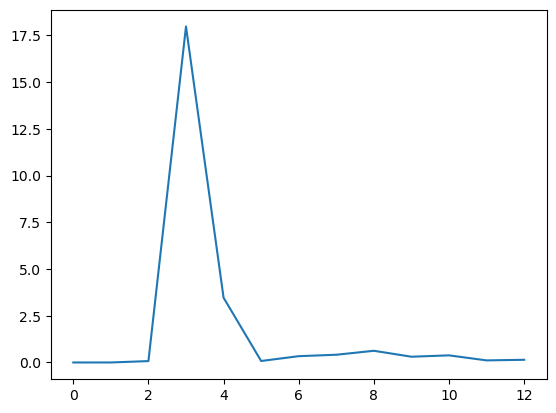

In [23]:
# rainfall_at_peak = get_data_at_peak_cell(year_cube, results_dict, 'x_idx', 'y_idx')
# plt.plot(rainfall_at_peak.data)
# np.nanmax(rainfall_at_peak.data)
rain = year_cube.data

# Rainfall at the grid cell with maximum flooding
rain_at_flood_cell = rain[:, y_idx, x_idx]

# Coordinates
times = year_cube.coord("time").points
x_coords = year_cube.coord("projection_x_coordinate").points
y_coords = year_cube.coord("projection_y_coordinate").points

rainfall_df = pd.DataFrame({"timestep": np.arange(len(times)),"rainfall_at_flood_cell": rain_at_flood_cell})

plt.plot(rainfall_df['rainfall_at_flood_cell'])

rainfall_peaks = []

for t in range(rain.shape[0]):
    arr = np.ma.filled(np.ma.masked_invalid(rain[t]), np.nan)

    if np.all(np.isnan(arr)):
        continue

    peak_y, peak_x = np.unravel_index(np.nanargmax(arr), arr.shape)

    dx = x_coords[peak_x] - x_coords[x_idx]
    dy = y_coords[peak_y] - y_coords[y_idx]

    rainfall_peaks.append({
        "timestep": t,
        "rainfall_at_flood_cell": rain[t, y_idx, x_idx],
        "max_rainfall": arr[peak_y, peak_x],
        "rain_peak_x_idx": peak_x,
        "rain_peak_y_idx": peak_y,
        "distance_from_flood_cell_km": np.hypot(dx, dy) / 1000,
        "same_grid_cell": peak_x == x_idx and peak_y == y_idx})

rainfall_peaks_df = pd.DataFrame(rainfall_peaks)

# print(rainfall_peaks_df.to_string(index=False))

radius = 1  # 1 cell in each direction

y0, y1 = max(0, y_idx-radius), min(rain.shape[1], y_idx+radius+1)
x0, x1 = max(0, x_idx-radius), min(rain.shape[2], x_idx+radius+1)

local_rainfall = []

for t in range(rain.shape[0]):
    arr = np.ma.filled(np.ma.masked_invalid(rain[t]), np.nan)
    neighbourhood = arr[y0:y1, x0:x1]

    local_rainfall.append({"timestep": t,"rainfall_at_flood_cell": arr[y_idx, x_idx],
        "max_rainfall_nearby": np.nanmax(neighbourhood) if np.any(np.isfinite(neighbourhood)) else np.nan,
        "max_rainfall_gridwide": np.nanmax(arr) if np.any(np.isfinite(arr)) else np.nan})

local_rainfall_df = pd.DataFrame(local_rainfall)
# print(local_rainfall_df.to_string(index=False))

/tmp/ipykernel_3012225/1984209034.py:25: RuntimeWarning: All-NaN slice encountered
  max_rain = np.nanmax(rain, axis=0)


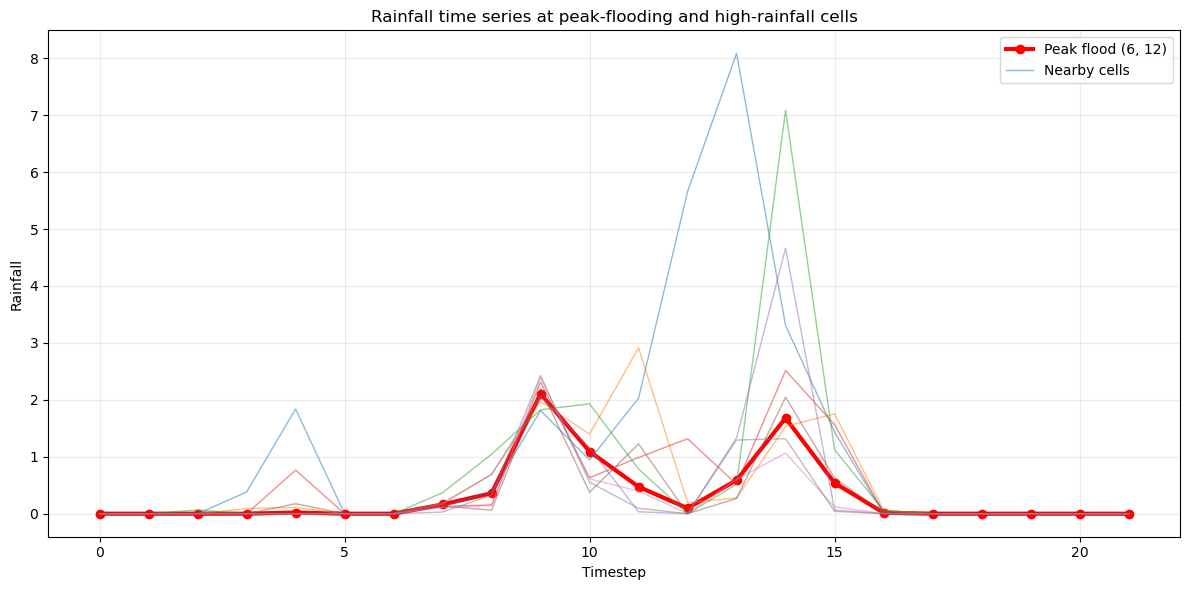

In [49]:
rain = np.ma.filled(year_cube.data, np.nan)
flood = np.ma.filled(area_cube[1, :, :].data, np.nan)

x_coords = year_cube.coord("projection_x_coordinate").points
y_coords = year_cube.coord("projection_y_coordinate").points

n_times, ny, nx = rain.shape

# --------------------------------------------------
# 1. Define cells to investigate
# --------------------------------------------------
cells = {(y_idx, x_idx): "peak_flood"}

# Add the surrounding 5 x 5 neighbourhood
radius = 1

for yi in range(max(0, y_idx-radius), min(ny, y_idx+radius+1)):
    for xi in range(max(0, x_idx-radius), min(nx, x_idx+radius+1)):
        cells.setdefault((yi, xi), "nearby")

# --------------------------------------------------
# 2. Identify cells with highest rainfall
# --------------------------------------------------
# Maximum rainfall across the 19 timesteps at each cell
max_rain = np.nanmax(rain, axis=0)

# Find the 20 cells with highest maximum rainfall
n_top = 20
valid = np.isfinite(max_rain)
top_flat = np.argsort(np.where(valid, max_rain, -np.inf).ravel())[::-1]
top_flat = [i for i in top_flat if valid.ravel()[i]][:n_top]

for flat_idx in top_flat:
    yi, xi = np.unravel_index(flat_idx, max_rain.shape)
    cells.setdefault((yi, xi), "high_rainfall")

# --------------------------------------------------
# 3. Summarise each cell
# --------------------------------------------------
records = []

for (yi, xi), category in cells.items():
    ts = rain[:, yi, xi]

    records.append({
        "y_idx": yi,
        "x_idx": xi,
        "category": category,
        "x_coord": x_coords[xi],
        "y_coord": y_coords[yi],
        "flooded_area_km2": flood[yi, xi],
        "max_rainfall": np.nanmax(ts) if np.any(np.isfinite(ts)) else np.nan,
        "total_rainfall": np.nansum(ts),
        "mean_rainfall": np.nanmean(ts) if np.any(np.isfinite(ts)) else np.nan,
        "rainfall_timeseries": ts.copy()
    })

cells_df = pd.DataFrame(records)

# print(
#     cells_df.drop(columns="rainfall_timeseries")
#     .sort_values(["category", "max_rainfall"], ascending=[True, False])
#     .to_string(index=False))


fig, ax = plt.subplots(figsize=(12, 6))

for _, row in cells_df.iterrows():
    ts = row["rainfall_timeseries"]

    if row["category"] == "peak_flood":
        ax.plot(ts, marker="o", linewidth=3, color="red",
                label=f"Peak flood ({row['y_idx']}, {row['x_idx']})")
    elif row["category"] == "nearby":
        ax.plot(ts, alpha=0.5, linewidth=1,
                label="Nearby cells" if not any(
                    l.get_label() == "Nearby cells" for l in ax.lines
                ) else "_nolegend_")
#     else:
#         ax.plot(ts, alpha=0.5, linewidth=1, linestyle="--",
#                 label="High-rainfall cells" if not any(
#                     l.get_label() == "High-rainfall cells" for l in ax.lines
#                 ) else "_nolegend_")

ax.set_xlabel("Timestep")
ax.set_ylabel("Rainfall")
ax.set_title("Rainfall time series at peak-flooding and high-rainfall cells")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

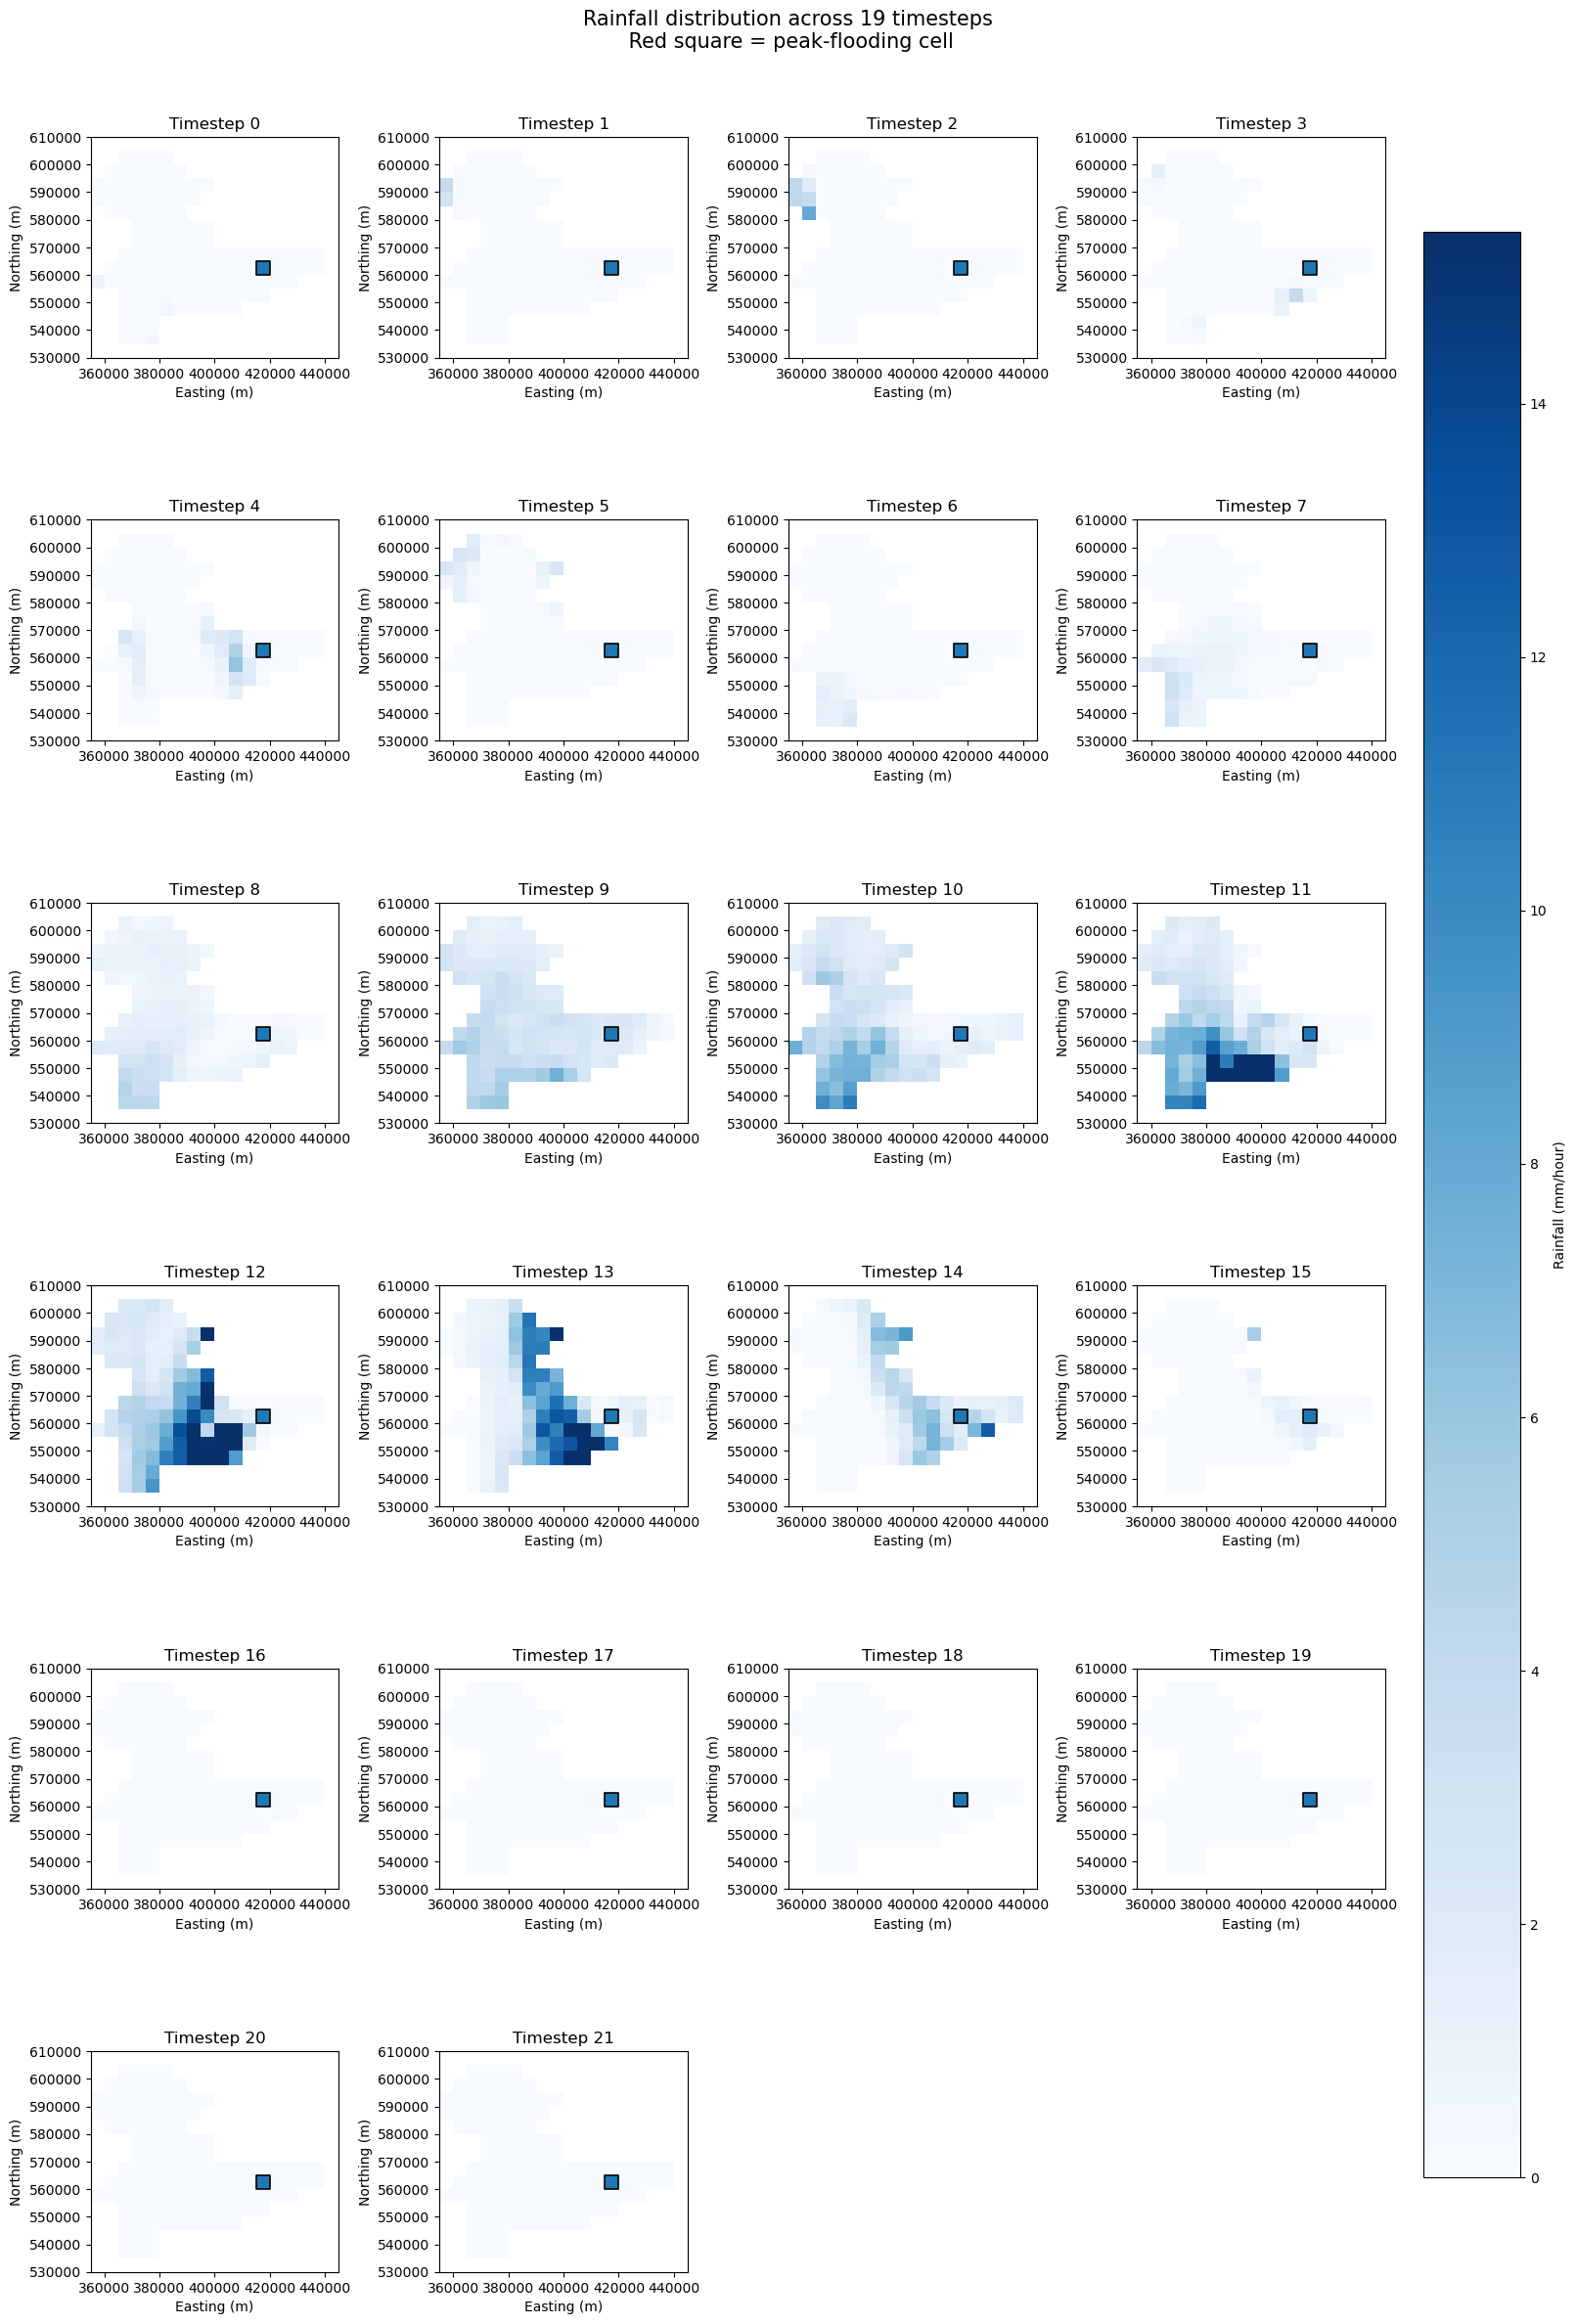

In [53]:
# --------------------------------------------------
# 1. Prepare rainfall and coordinates
# --------------------------------------------------
rain = np.ma.masked_invalid(
    np.ma.filled(year_cube.data, np.nan))

x_coords = year_cube.coord("projection_x_coordinate").points
y_coords = year_cube.coord("projection_y_coordinate").points

n_times = rain.shape[0]

# Use one consistent colour scale across all timesteps
valid_rain = rain.compressed()
vmin = 0
vmax = np.percentile(valid_rain, 99) if len(valid_rain) else 1

# Peak-flooding cell coordinates
peak_x = x_coords[x_idx]
peak_y = y_coords[y_idx]

# --------------------------------------------------
# 2. Create subplot grid
# --------------------------------------------------
ncols = 4
nrows = int(np.ceil(n_times / ncols))

fig, axes = plt.subplots(nrows, ncols,figsize=(16, 4 * nrows),constrained_layout=True)

axes = np.asarray(axes).ravel()

# --------------------------------------------------
# 3. Plot rainfall for each timestep
# --------------------------------------------------
for t, ax in enumerate(axes[:n_times]):

    im = ax.pcolormesh(x_coords, y_coords, rain[t],cmap="Blues",vmin=vmin,vmax=vmax,shading="auto")

    # Highlight the peak-flooding cell
    ax.scatter(peak_x, peak_y,marker="s",s=100,facecolors=None,edgecolors="black",linewidths=1.2,zorder=5)

    ax.set_title(f"Timestep {t}")
    ax.set_aspect("equal")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

# Hide unused subplot
for ax in axes[n_times:]:
    ax.set_visible(False)

# Shared colour bar
cbar = fig.colorbar(im,ax=axes[:n_times].tolist(),shrink=0.85,pad=0.02)
cbar.set_label(f"Rainfall ({year_cube.units})")

fig.suptitle("Rainfall distribution across 19 timesteps\n Red square = peak-flooding cell",fontsize=15)

plt.show()

## ------------------------------------------------------------ ###
## Loop through catchments processing
## ------------------------------------------------------------ ###